## Question 1
### Import Libraries

In [10]:
import numpy as np
import pandas as pd
import re
from tqdm import tqdm

import gensim
from gensim.models import Word2Vec
from gensim.parsing.preprocessing import STOPWORDS

from keras.models import Sequential
from keras.layers import LSTM, Dense, RepeatVector, TimeDistributed
import matplotlib.pyplot as plt


### Config

In [11]:
CSV_PATH = "test.csv"
TEXT_COL = 2
EMBED_DIM = 100
N_STEPS_IN = 3
N_STEPS_OUT = 2
EPOCHS = 5
INCLUDE_STOPWORDS = False


### Preprocessing functions

In [12]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z.!? ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def split_sentences(text):
    sents = re.split(r"[.!?]", text)
    sents = [s.strip() for s in sents if s.strip()]
    return sents

def tokenize(sent, include_stopwords=True):
    tokens = sent.split()
    if not include_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS]
    return tokens


### Load data

In [ ]:
# Load and clean text
df = pd.read_csv(CSV_PATH, header=None)
texts = df.iloc[:, TEXT_COL].astype(str).tolist()
texts = [clean_text(t) for t in texts]

docs_tokens = []
for t in texts:
    sents = split_sentences(t)
    if not sents:
        continue
    longest = max(sents, key=lambda s: len(s.split()))
    tokens = tokenize(longest, INCLUDE_STOPWORDS)
    if len(tokens) >= N_STEPS_IN + N_STEPS_OUT:
        docs_tokens.append(tokens)

print("Num docs used:", len(docs_tokens))


Num docs used: 7574


### Word2Vec Model

In [ ]:
# Train Word2Vec model, 100 dimensions
w2v_model = Word2Vec(
    sentences=docs_tokens,
    vector_size=EMBED_DIM,
    window=5,
    min_count=2,
    workers=4
)

def tokens_to_matrix(tokens):
    vecs = [w2v_model.wv[t] for t in tokens if t in w2v_model.wv]
    if len(vecs) < N_STEPS_IN + N_STEPS_OUT:
        return None
    return np.vstack(vecs)


### Construct the LSTM Input Sequence

In [ ]:
# Build input/output sequences for LSTM
def split_sequences(seq_mat, n_steps_in, n_steps_out):
    X, y = [], []
    for i in range(len(seq_mat)):
        end_ix = i + n_steps_in
        out_end_ix = end_ix + n_steps_out
        if out_end_ix > len(seq_mat):
            break
        X.append(seq_mat[i:end_ix, :])
        y.append(seq_mat[end_ix:out_end_ix, :])
    return np.array(X), np.array(y)

X_list, y_list = [], []

for tokens in tqdm(docs_tokens, desc="Building sequences"):
    mat = tokens_to_matrix(tokens)
    if mat is None:
        continue
    X_doc, Y_doc = split_sequences(mat, N_STEPS_IN, N_STEPS_OUT)
    if len(X_doc) == 0:
        continue
    X_list.append(X_doc)
    y_list.append(Y_doc)

X = np.vstack(X_list)
y = np.vstack(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)

N_FEATURES = X.shape[2]


Building sequences: 100%|██████████| 7574/7574 [00:00<00:00, 41125.95it/s]


X shape: (80957, 3, 100)
y shape: (80957, 2, 100)


### Training LSTM, tanh & ReLU

In [ ]:
def build_model(activation="tanh"):
    model = Sequential()
    model.add(LSTM(200, activation=activation, input_shape=(N_STEPS_IN, N_FEATURES)))
    model.add(RepeatVector(N_STEPS_OUT))
    model.add(LSTM(200, activation=activation, return_sequences=True))
    model.add(TimeDistributed(Dense(N_FEATURES)))
    model.compile(optimizer='adam', loss='mse')
    return model

# Train tanh activation model and compute RMSE
def train_and_rmse(activation):
    model = build_model(activation)
    model.fit(X, y, epochs=EPOCHS, verbose=1)
    y_pred = model.predict(X, verbose=0)
    errs = np.sqrt(np.mean((y_pred - y)**2, axis=(1,2)))
    return model, errs

print("Training tanh...")
model_tanh, err_tanh = train_and_rmse("tanh")

print("Training relu...")
model_relu, err_relu = train_and_rmse("relu")


Training tanh...
Epoch 1/5


/Users/brookechen/Library/Python/3.9/lib/python/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2530/2530 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 0.0542
Epoch 2/5
2530/2530 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.0526
Epoch 3/5
  40/2530 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - loss: 0.0515

### Plot RMSE histogram + Select better activation function

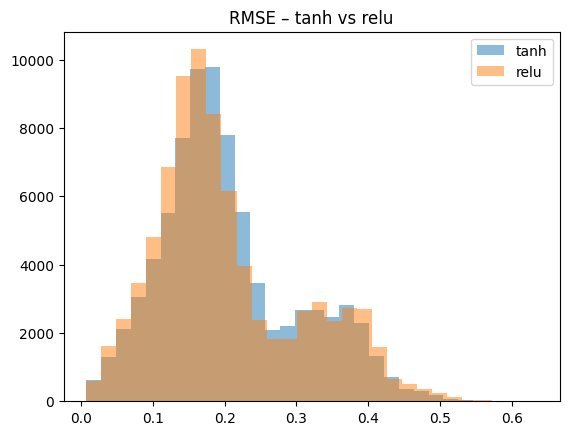

Mean tanh: 0.20598993
Mean relu: 0.2035242
Best activation: relu


In [ ]:
plt.hist(err_tanh, bins=30, alpha=0.5, label="tanh")
plt.hist(err_relu, bins=30, alpha=0.5, label="relu")
plt.legend()
plt.title("RMSE – tanh vs relu")
plt.show()

print("Mean tanh:", err_tanh.mean())
print("Mean relu:", err_relu.mean())

best_model = model_tanh if err_tanh.mean() < err_relu.mean() else model_relu
best_name = "tanh" if best_model is model_tanh else "relu"
print("Best activation:", best_name)




### Predict the last two words of the longest document

In [ ]:
longest_doc = max(docs_tokens, key=len)
long_mat = tokens_to_matrix(longest_doc)

x_input = long_mat[-(N_STEPS_IN + N_STEPS_OUT):-N_STEPS_OUT, :]
x_input = x_input.reshape((1, N_STEPS_IN, N_FEATURES))
y_pred = best_model.predict(x_input, verbose=0)[0]

def vec_to_words(vec):
    return w2v_model.wv.similar_by_vector(vec, topn=5)

print("True last 2 tokens:", longest_doc[-2:])
for i, v in enumerate(y_pred):
    print(f"Predicted {i+1}:", vec_to_words(v))


True last 2 tokens: ['rebel', 'slogans']
Predicted 1: [('says', 0.999875545501709), ('ap', 0.9998726844787598), ('set', 0.9998601675033569), ('international', 0.9998473525047302), ('today', 0.9998462796211243)]
Predicted 2: [('ap', 0.9998806118965149), ('says', 0.9998801350593567), ('international', 0.9998611807823181), ('yesterday', 0.9998601078987122), ('set', 0.9998584389686584)]
